In [1]:
import numpy as np

from qiskit import QuantumCircuit, QuantumRegister, AncillaRegister, ClassicalRegister, transpile
from qiskit.circuit.library import RYGate
from qiskit_aer import AerSimulator

In [6]:
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, AncillaRegister, ClassicalRegister
from qiskit import transpile
from qiskit_aer import AerSimulator

def initial_prior(
    qreg_active, qreg_features
):
    qc = QuantumCircuit(qreg_active, qreg_features)
    
    qc.h(qreg_active)
    qc.h(qreg_features)
    
    return qc

def proposal(
    qreg_active, qreg_features, qreg_proposal,
    delta=0.25
):
    qc = QuantumCircuit(qreg_active, qreg_features, qreg_proposal)
    
    qc.h(qreg_proposal[0])
    
    for i in range(qreg_active.size):
        qc.cry(delta * np.pi, qreg_proposal[0], qreg_active[i])
    
    for j in range(qreg_features.size):
        qc.cry(delta * np.pi / 2, qreg_proposal[0], qreg_features[j])

    return qc

def acceptance(
    qreg_active, qreg_features, qreg_accept,
    alpha=0.5
):
    qc = QuantumCircuit(qreg_active, qreg_features, qreg_accept)

    all_wavelet_qubits = list(qreg_active) + list(qreg_features)
    qc.mcx(all_wavelet_qubits, qreg_accept[0])
    
    qc.cry(2 * np.arcsin(np.sqrt(alpha)), qreg_features[-1], qreg_accept[0])

    return qc

def qmcmc(
    n_params,
    n_wavelets_max=10,
    delta=0.25, beta=0.5,
    barriers=False
):
    qreg_active = QuantumRegister(n_wavelets_max, name="qreg_active")
    qreg_features = QuantumRegister(n_wavelets_max * n_params, name="qreg_features")
    qreg_proposal = AncillaRegister(1, name="qreg_proposal")
    qreg_accept = AncillaRegister(1, name="qreg_accept")
    
    total_meas_qubits = n_wavelets_max + (n_wavelets_max * n_params)
    creg_meas = ClassicalRegister(total_meas_qubits, name="creg_meas")
    
    qc = QuantumCircuit(
        qreg_active, qreg_features, qreg_proposal, qreg_accept,
        creg_meas
    )
    
    # 1. Initialization
    qc_initial_prior = initial_prior(
        qreg_active, qreg_features
    )
    qc.compose(qc_initial_prior, qreg_active[:] + qreg_features[:], inplace=True)
    
    if barriers: qc.barrier()
    
    # 2. Proposal
    qc_proposal = proposal(
        qreg_active, qreg_features, qreg_proposal,
        delta=delta
    )
    qc.compose(qc_proposal, qreg_active[:] + qreg_features[:] + qreg_proposal[:], inplace=True)

    if barriers: qc.barrier()
    
    # 3. Acceptance
    qc_accept = acceptance(
        qreg_active, qreg_features, qreg_accept,
        beta=0.5
    )
    qc.compose(qc_accept, qreg_active[:] + qreg_features[:] + qreg_accept[:], inplace=True)

    if barriers: qc.barrier()
    
    # 4: Measurement
    all_target_qubits = list(qreg_active) + list(qreg_features)
    qc.measure(all_target_qubits, creg_meas)
    
    return qc

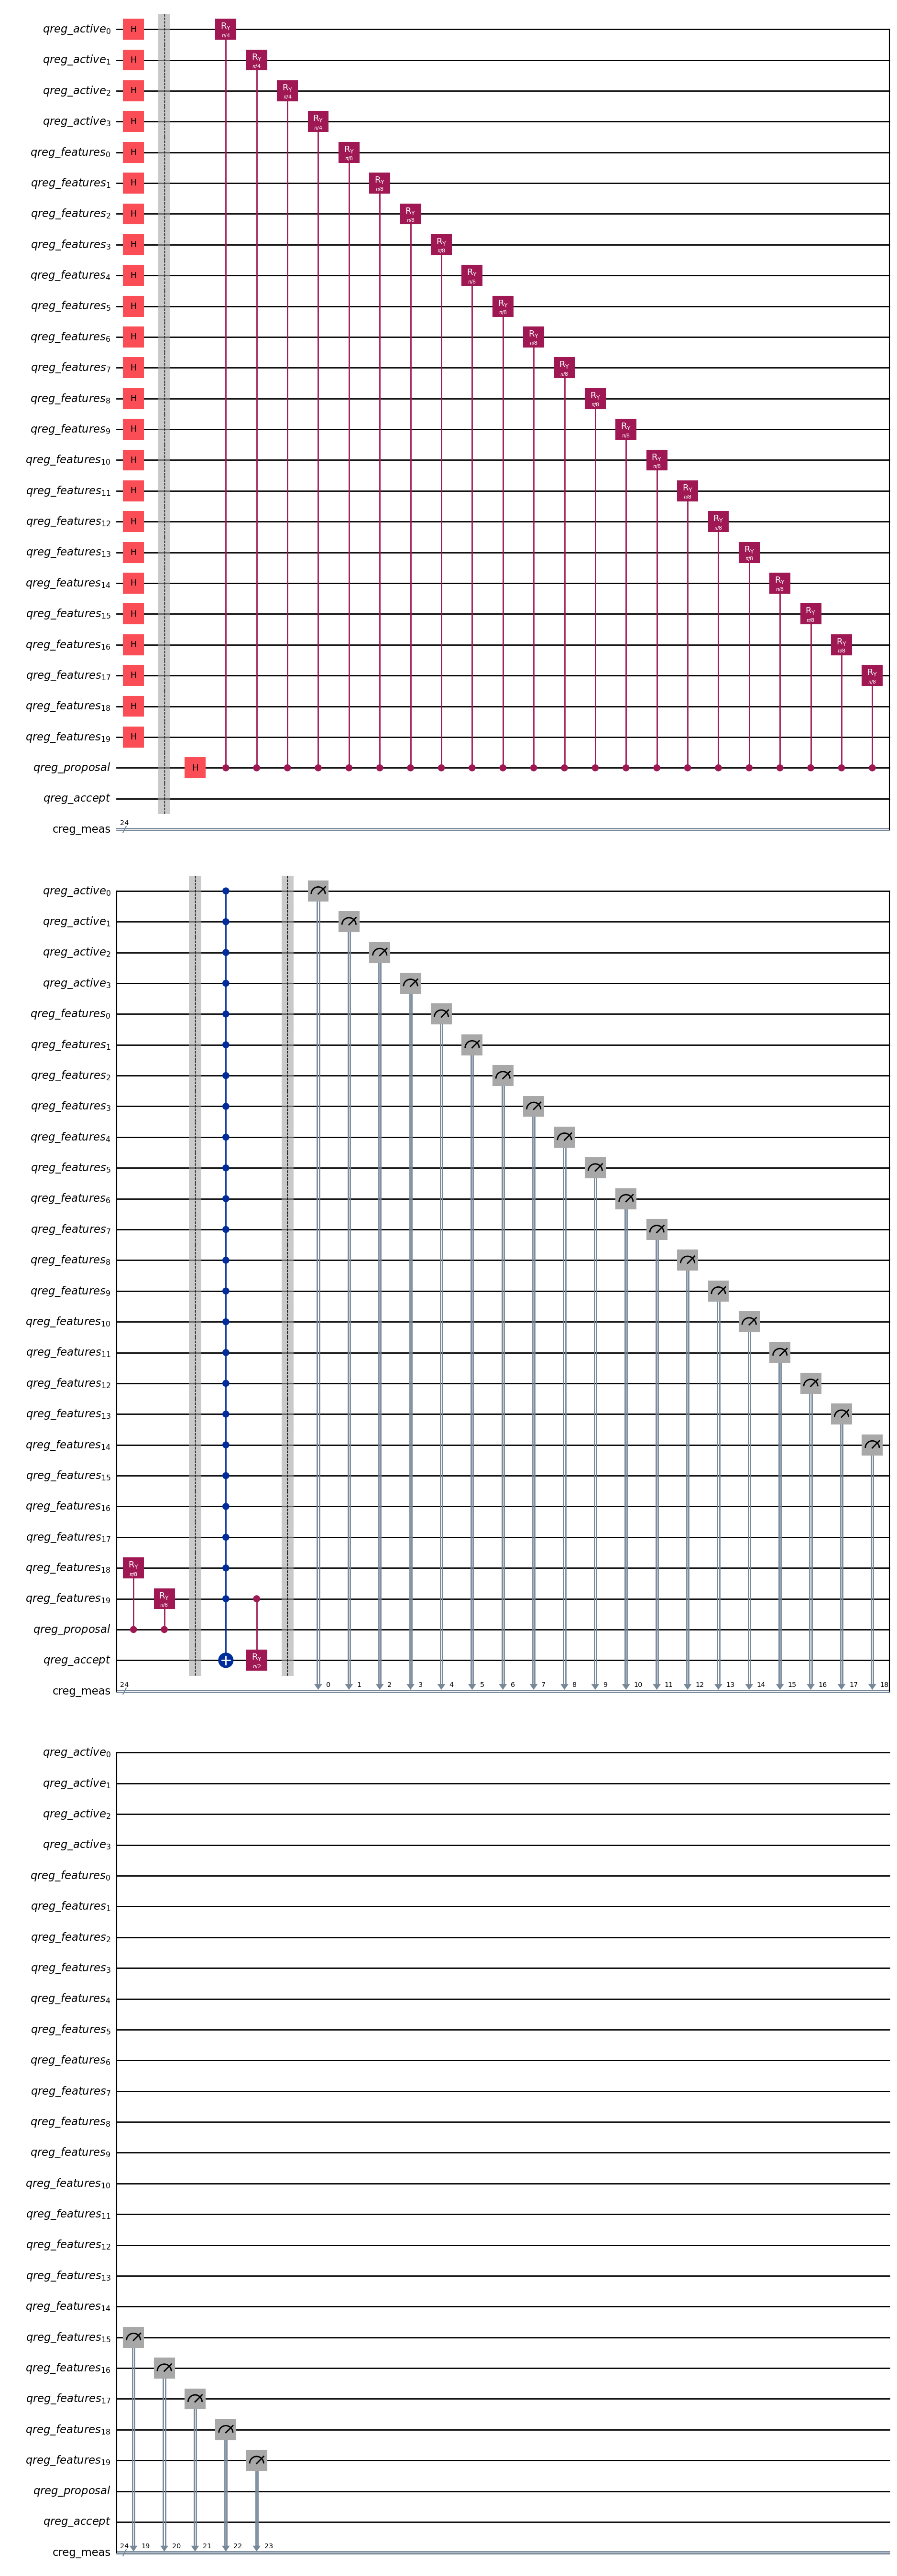

In [11]:
qc_mcmc = qmcmc(
    n_params=5,
    n_wavelets_max=4,
    delta=0.25,
    beta=0.5,
    barriers=True
)

qc_mcmc.draw(output="mpl")

In [13]:
aer_simulator = AerSimulator()

qc_mcmc_transpiled = transpile(qc_mcmc, aer_simulator)
result = aer_simulator.run(qc_mcmc_transpiled, shots=1024).result()
counts = result.get_counts()

print("Counts:")
print(counts)


KeyboardInterrupt

